<a href="https://colab.research.google.com/github/Arthxzs/Analise_Eleitoral_2026/blob/main/An%C3%A1lise_vota%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Montagem do drive para acessar os arquivos

In [183]:
from google.colab import drive
import os
import numpy as np
import matplotlib.pyplot as plt

drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive/Colab Notebooks/Votacao/data")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Montagem dos dois DF

In [184]:
import pandas as pd

usecols1 = ["NR_TURNO", "SG_UF", "SG_UE", "NM_UE", "NM_MUNICIPIO", "CD_MUNICIPIO", "QT_APTOS", "QT_COMPARECIMENTO", "QT_VOTOS_BRANCOS", "DS_CARGO", "QT_ABSTENCOES", "QT_TOTAL_VOTOS_VALIDOS", "QT_TOTAL_VOTOS_NULOS"] # Selecionando colunas relevantes para a análise
df1 = pd.read_csv("detalhe_votacao_munzona_2026_BRASIL.csv", encoding="ISO-8859-1", sep=";", usecols=usecols1) #Detalhes da votação

usecols2 = ["NM_TIPO_ELEICAO", "SG_UF", "SG_UE", "NM_UE", "CD_MUNICIPIO", "NR_TURNO", "DS_ELEICAO", "NM_MUNICIPIO", "DS_CARGO", "QT_VOTOS_NOMINAIS", "NR_CANDIDATO", "NM_CANDIDATO", "NM_PARTIDO", "QT_VOTOS_NOMINAIS_VALIDOS"]
df2 = pd.read_csv("votacao_candidato_munzona_2026_BRASIL.csv", encoding="ISO-8859-1", sep=";", usecols=usecols2) # Números de votação dos candidatos



# Números da eleição

In [185]:
numeros_pres = (df1["DS_CARGO"] == "Presidente") #& (df1["NR_TURNO"] == 2) # & (df1["SG_UF"] == "ZZ")

numeros_pres = (df1[numeros_pres]
                .groupby(["NR_TURNO", "DS_CARGO"])[["QT_APTOS", "QT_COMPARECIMENTO", "QT_ABSTENCOES", "QT_TOTAL_VOTOS_NULOS", "QT_VOTOS_BRANCOS", "QT_TOTAL_VOTOS_VALIDOS"]]
                .sum(numeric_only=True).sort_values("QT_TOTAL_VOTOS_VALIDOS", ascending=True)
                )

numeros_pres = (numeros_pres
                .rename(columns={"QT_APTOS": "Eleitores aptos", "QT_COMPARECIMENTO": "Comparecimento", "QT_ABSTENCOES": "Abstenções", "QT_TOTAL_VOTOS_NULOS": "Votos nulos", "QT_VOTOS_BRANCOS": "Votos brancos", "QT_TOTAL_VOTOS_VALIDOS": "Votos nominais"})
                )

numeros_pres = (numeros_pres
                .rename_axis(index={"NR_TURNO": "Turno", "DS_CARGO": "Cargo"})
                )

#numeros_t1 = numeros_t1.reset_index()

display(numeros_pres)

,,Eleitores aptos,Comparecimento,Abstenções,Votos nulos,Votos brancos,Votos nominais
Turno,Cargo,,,,,,
1,Presidente,158745502,125275835,33469244,3674249,2300798,119300788
2,Presidente,158745502,128236074,30509005,2723305,1430496,124082273


# Relação de porcentagem entre os números

In [186]:
numeros_pres["% Comparecimento"] = round(((numeros_pres["Comparecimento"] / numeros_pres["Eleitores aptos"]) * 100), 2)
numeros_pres["% Abstenções"] = round(((numeros_pres["Abstenções"] / numeros_pres["Eleitores aptos"]) * 100), 2)
numeros_pres["% Votos em branco"] = round(((numeros_pres["Votos brancos"] / numeros_pres["Comparecimento"]) * 100), 2)
numeros_pres["% Votos nulo"] = round(((numeros_pres["Votos nulos"] / numeros_pres["Comparecimento"]) * 100), 2)
numeros_pres["% Votos nominais"] = round((numeros_pres["Votos nominais"] / (numeros_pres["Comparecimento"]) * 100), 2)

display(numeros_pres["Eleitores aptos"])
print("-------------------------------")
display(numeros_pres["% Abstenções"])
print("-------------------------------")
display(numeros_pres["% Votos em branco"])
print("-------------------------------")
display(numeros_pres["% Votos nulo"])
print("-------------------------------")
display(numeros_pres["% Votos nominais"])

,,Eleitores aptos
Turno,Cargo,
1,Presidente,158745502
2,Presidente,158745502


-------------------------------


,,% Abstenções
Turno,Cargo,
1,Presidente,21.08
2,Presidente,19.22


-------------------------------


,,% Votos em branco
Turno,Cargo,
1,Presidente,1.84
2,Presidente,1.12


-------------------------------


,,% Votos nulo
Turno,Cargo,
1,Presidente,2.93
2,Presidente,2.12


-------------------------------


,,% Votos nominais
Turno,Cargo,
1,Presidente,95.23
2,Presidente,96.76


# Números de votação primeiro e segundo turno

In [187]:
def votacao_candidatos(turno):
  filtro = (df2["NR_TURNO"] == turno) & (df2["DS_CARGO"] == "Presidente")
  votacao_pres = df2[filtro].groupby(["NR_TURNO", "DS_CARGO", "NR_CANDIDATO", "NM_CANDIDATO"])[["QT_VOTOS_NOMINAIS_VALIDOS"]].sum().sort_values("QT_VOTOS_NOMINAIS_VALIDOS", ascending= False)
  votacao_pres = votacao_pres.rename(columns={"QT_VOTOS_NOMINAIS_VALIDOS": "Votos nominais válidos"})
  votacao_pres = votacao_pres.rename_axis(index={"NR_TURNO": "Turno", "DS_CARGO": "Cargo", "NR_CANDIDATO": "Número", "NM_CANDIDATO": "Candidato"})
  votacao_pres["% dos válidos"] = round((votacao_pres["Votos nominais válidos"] / votacao_pres["Votos nominais válidos"].sum() * 100), 2)
  return votacao_pres

votacao_t1 = votacao_candidatos(1)
votacao_t2 = votacao_candidatos(2)

display(votacao_t1)
display(votacao_t2)

Votos nominais válidos  \
Turno Cargo      Número Candidato                                                   
1     Presidente 22     FLAVIO NANTES BOLSONARO                          56104503   
                 13     LUIZ INÁCIO LULA DA SILVA                        53879538   
                 70     AUGUSTO JORGE CURY                                3448569   
                 14     RENAN ANTONIO FERREIRA DOS SANTOS                 2675887   
                 55     RONALDO RAMOS CAIADO                              2605148   
                 30     ROMEU ZEMA NETO                                    326488   
                 80     SAMARA MARTINS DA SILVA FEITOSA                    122911   
                 16     HERTZ DA CONCEICAO DIAS                             43103   
                 27     CLARIANA ZACARKIM BARAO                             40043   
                 21     EDMILSON SILVA COSTA                                22693   
                 35     WILSON GRASSI JUNIOR                                16881   
                 29     RUI COSTA PIMENTA                                   15024   

                                                           % dos válidos  
Turno Cargo      Número Candidato                                         
1     Presidente 22     FLAVIO NANTES BOLSONARO                    47.03  
                 13     LUIZ INÁCIO LULA DA SILVA                  45.16  
                 70     AUGUSTO JORGE CURY                          2.89  
                 14     RENAN ANTONIO FERREIRA DOS SANTOS           2.24  
                 55     RONALDO RAMOS CAIADO                        2.18  
                 30     ROMEU ZEMA NETO                             0.27  
                 80     SAMARA MARTINS DA SILVA FEITOSA             0.10  
                 16     HERTZ DA CONCEICAO DIAS                     0.04  
                 27     CLARIANA ZACARKIM BARAO                     0.03  
                 21     EDMILSON SILVA COSTA                        0.02  
                 35     WILSON GRASSI JUNIOR                        0.01  
                 29     RUI COSTA PIMENTA                           0.01

Votos nominais válidos  \
Turno Cargo      Número Candidato                                           
2     Presidente 13     LUIZ INÁCIO LULA DA SILVA                64256232   
                 22     FLAVIO NANTES BOLSONARO                  59826041   

                                                   % dos válidos  
Turno Cargo      Número Candidato                                 
2     Presidente 13     LUIZ INÁCIO LULA DA SILVA          51.79  
                 22     FLAVIO NANTES BOLSONARO            48.21

# Diferença entre primeiro e segundo turno para os candidatos



In [188]:
# Os finalistas são os candidatos do 2º turno
finalistas = votacao_t2.index.get_level_values("Número").tolist()

cand_t1 = votacao_t1.reset_index().set_index("Número").loc[finalistas]
cand_t2 = votacao_t2.reset_index().set_index("Número").loc[finalistas]

ganho_finalistas = pd.DataFrame({"Candidato": cand_t2["Candidato"], "Votos 1º turno": cand_t1["Votos nominais válidos"], "Votos 2º turno": cand_t2["Votos nominais válidos"]})
ganho_finalistas["Diferença"] = ganho_finalistas["Votos 2º turno"] - ganho_finalistas["Votos 1º turno"]
ganho_finalistas["Aumentou?"] = ganho_finalistas["Diferença"] > 0

display(ganho_finalistas)

,Candidato,Votos 1º turno,Votos 2º turno,Diferença,Aumentou?
Número,,,,,
13,LUIZ INÁCIO LULA DA SILVA,53879538,64256232,10376694,True
22,FLAVIO NANTES BOLSONARO,56104503,59826041,3721538,True


In [189]:
# Decomposição do ganho dos finalistas entre os turnos:
# ganho = votos dos eliminados no 1º turno + queda de abstenções + queda de nulos + queda de brancos (+ resíduo)
total_t1 = numeros_pres.loc[(1, "Presidente")]
total_t2 = numeros_pres.loc[(2, "Presidente")]

eliminados_t1 = votacao_t1["Votos nominais válidos"].sum() - cand_t1["Votos nominais válidos"].sum()
ganho_total = ganho_finalistas["Diferença"].sum()

composicao_ganho = pd.DataFrame({"Votos": [eliminados_t1,
                                           total_t1["Abstenções"] - total_t2["Abstenções"],
                                           total_t1["Votos nulos"] - total_t2["Votos nulos"],
                                           total_t1["Votos brancos"] - total_t2["Votos brancos"]]},
                                index=["Votos dos candidatos eliminados no 1º turno", "Queda de abstenções", "Queda de votos nulos", "Queda de votos brancos"])
composicao_ganho.loc["Resíduo (diferença não explicada pelos dados)"] = ganho_total - composicao_ganho["Votos"].sum()
composicao_ganho.loc["Ganho total dos finalistas"] = ganho_total

display(composicao_ganho)

,Votos
Votos dos candidatos eliminados no 1º turno,9316747.0
Queda de abstenções,2960239.0
Queda de votos nulos,950944.0
Queda de votos brancos,870302.0
Resíduo (diferença não explicada pelos dados),0.0
Ganho total dos finalistas,14098232.0


# Número de municípios

In [190]:
nr_municipios_br = 5569 # Tirado do site do IBGE: https://www.ibge.gov.br/geociencias/organizacao-do-territorio/malhas-territoriais/15774-malhas.html?=&t=sobre

mun_br = df2["SG_UF"] != "ZZ"
nr_municipio = df2[mun_br][["CD_MUNICIPIO"]].nunique().to_frame()
nr_municipio = nr_municipio.rename(columns={0: "N municípios"})

display(nr_municipio)

#Brasília e Fernando de Noronha não são considerados municípios propriamente ditos pelo IBGE porém são considerados nessa contagem do TSE, por isso a diferença

,N municípios
CD_MUNICIPIO,5571


# Votação por município, estado e região
Contendo a diferença entre primeiro e segundo turno

Votação por município

In [191]:
# Chave do município: SG_UF + CD_MUNICIPIO (o nome do município se repete entre UFs)
filtro_2 = (df2["DS_CARGO"] == "Presidente") & (df2["NR_CANDIDATO"].isin(finalistas)) # & (df2["SG_UF"] == "PB")

votacao_pres_b = df2[filtro_2].groupby(["SG_UF", "CD_MUNICIPIO", "NM_MUNICIPIO", "NR_TURNO", "NR_CANDIDATO"])[["QT_VOTOS_NOMINAIS_VALIDOS"]].sum()
votacao_pres_b = votacao_pres_b.unstack(["NR_TURNO", "NR_CANDIDATO"], fill_value=0)
votacao_pres_b.columns = [f"t{turno}_{cand}" for _, turno, cand in votacao_pres_b.columns]
votacao_pres_b = votacao_pres_b.reset_index()

# Regra do vencedor (13 ou 22; 0 = empate exato), escrita uma vez e usada em município, UF e região
def definir_vencedor(df, col_13, col_22):
    return np.select([df[col_13] > df[col_22], df[col_22] > df[col_13]], [13, 22], default=0)

votacao_pres_b["Vencedor_turno_1"] = definir_vencedor(votacao_pres_b, "t1_13", "t1_22")
votacao_pres_b["Vencedor_turno_2"] = definir_vencedor(votacao_pres_b, "t2_13", "t2_22")
votacao_pres_b["Margem_turno_1"] = votacao_pres_b["t1_13"] - votacao_pres_b["t1_22"]
votacao_pres_b["Margem_turno_2"] = votacao_pres_b["t2_13"] - votacao_pres_b["t2_22"]

colunas_votos = ["t1_13", "t1_22", "t2_13", "t2_22"]


# Conferências: as somas devem fechar com os totais por candidato e turno
print("Números de votação por município")
display(votacao_pres_b.head()) #Tá por ordem dos estados
print("---------------------------------------------------")
print("Votação entre os candidatos finalistas nos 2 turnos")
display(votacao_pres_b[colunas_votos].sum())
print("-------------------------------")
print("Número de municípios analisados") # Municípios nacionais + internacionais
display(df2[df2["DS_CARGO"] == "Presidente"]["CD_MUNICIPIO"].nunique())

Números de votação por município


,SG_UF,CD_MUNICIPIO,NM_MUNICIPIO,t1_13,t1_22,t2_13,t2_22,Vencedor_turno_1,Vencedor_turno_2,Margem_turno_1,Margem_turno_2
0,AC,1007,BUJARI,2394,5531,2454,5034,22,22,-3137,-2580
1,AC,1015,CAPIXABA,1732,4227,1663,3825,22,22,-2495,-2162
2,AC,1023,PORTO ACRE,2658,7926,2752,7534,22,22,-5268,-4782
3,AC,1031,SANTA ROSA DO PURUS,1384,1258,1476,1123,13,13,126,353
4,AC,1040,MARECHAL THAUMATURGO,3365,5369,2706,4017,22,22,-2004,-1311


---------------------------------------------------
Votação entre os candidatos finalistas nos 2 turnos


,0
t1_13,53879538
t1_22,56104503
t2_13,64256232
t2_22,59826041


-------------------------------
Número de municípios analisados


5757

Votação por região e estado

In [192]:
regioes = {"AC": "Norte", "AP": "Norte", "AM": "Norte", "PA": "Norte", "RO": "Norte", "RR": "Norte", "TO": "Norte",
           "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste", "PB": "Nordeste",
           "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste", "SE": "Nordeste",
           "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
           "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
           "PR": "Sul", "RS": "Sul", "SC": "Sul", "ZZ": "Exterior"}

# Tirando o ZZ para só ter dados nacionais pras regiões
estados_br = votacao_pres_b[votacao_pres_b["SG_UF"] != "ZZ"].copy()

votacao_pres_b["Regiao"] = votacao_pres_b["SG_UF"].map(regioes)
estados_br["Regiao"] = estados_br["SG_UF"].map(regioes)

votos_uf = votacao_pres_b.groupby("SG_UF")[colunas_votos].sum()
votos_regiao = votacao_pres_b.groupby("Regiao")[colunas_votos].sum()

for tabela in (votos_uf, votos_regiao):
    tabela["Vencedor_turno_1"] = definir_vencedor(tabela, "t1_13", "t1_22")
    tabela["Vencedor_turno_2"] = definir_vencedor(tabela, "t2_13", "t2_22")

print("Votação por região")
display(votos_regiao)
print("-------------------------------------------------------------------------------------")
print("Votação por estado")
display(votos_uf)

Votação por região


,t1_13,t1_22,t2_13,t2_22,Vencedor_turno_1,Vencedor_turno_2
Regiao,,,,,,
Centro-Oeste,2963043,5133436,3733919,5603867,22,22
Exterior,157387,143900,200154,171497,13,13
Nordeste,21494584,10398973,24450432,10796736,13,13
Norte,4550602,5009437,5024626,5023547,22,13
Sudeste,19237398,24899609,24037731,26844501,22,22
Sul,5476524,10519148,6809370,11385893,22,22


-------------------------------------------------------------------------------------
Votação por estado


,t1_13,t1_22,t2_13,t2_22,Vencedor_turno_1,Vencedor_turno_2
SG_UF,,,,,,
AC,134770,302807,144513,287715,22,22
AL,995459,735718,1152621,744140,13,13
AM,1046996,976764,1145783,975245,13,13
AP,212503,212278,222968,198674,13,13
BA,5664771,2442585,6485258,2608761,13,13
CE,3555263,1756850,4036124,1819478,13,13
DF,675627,909616,825224,979542,22,22
ES,850028,1233194,1001965,1294504,22,22
GO,1188880,2051888,1585555,2345334,22,22


Vencedores por cidade nos estados

In [193]:
def porcentagem_cidade_estados(candidato):
  porcentagem_cuf = pd.DataFrame({f"% cidades do {candidato} - 1º turno": (estados_br["Vencedor_turno_1"] == candidato).groupby(estados_br["SG_UF"]).mean() * 100,
                               f"% cidades do {candidato} - 2º turno": (estados_br["Vencedor_turno_2"] == candidato).groupby(estados_br["SG_UF"]).mean() * 100})
  porcentagem_cuf = porcentagem_cuf.sort_values(f"% cidades do {candidato} - 1º turno", ascending=False)
  return porcentagem_cuf

porcentagem_cidade_estados_13 = porcentagem_cidade_estados(13)
porcentagem_cidade_estados_22 = porcentagem_cidade_estados(22)

#print("Porcentagem de cidades onde Lula venceu")
#display(round((porcentagem_cidade_estados_13), 2))
print("Porcentagem de cidades onde Flávio venceu")
display(round((porcentagem_cidade_estados_22), 2))

Porcentagem de cidades onde Flávio venceu


,% cidades do 22 - 1º turno,% cidades do 22 - 2º turno
SG_UF,,
DF,100.00,100.00
RO,100.00,100.00
SC,98.31,97.97
SP,93.80,88.84
MT,93.66,92.25
RR,93.33,93.33
MS,92.41,87.34
RS,91.55,87.73
RJ,90.22,80.43


# Inversões e variação entre primeiro e segundo turno

In [194]:
 # Definição: inversão = vencedor diferente nos dois turnos, sem empate em nenhum deles
filtro_inv = (estados_br["Vencedor_turno_1"] != estados_br["Vencedor_turno_2"]) & (estados_br["Vencedor_turno_1"] != 0) & (estados_br["Vencedor_turno_2"] != 0)
inversoes = estados_br[filtro_inv]

inversoes_uf = votos_uf[votos_uf["Vencedor_turno_1"] != votos_uf["Vencedor_turno_2"]]
inversoes_regiao = votos_regiao[votos_regiao["Vencedor_turno_1"] != votos_regiao["Vencedor_turno_2"]]

def inversoes_municipio(candidato):
  inversao_mun = pd.Series({f"Total de municípios que inverteram": len(inversoes),
                                  f"Inverteram a favor do {candidato}": (inversoes["Vencedor_turno_2"] == candidato).sum()})
  return inversao_mun

empates = pd.Series({"Municípios com empate no 1º turno": (estados_br["Vencedor_turno_1"] == 0).sum(),
                     "Municípios com empate no 2º turno": (estados_br["Vencedor_turno_2"] == 0).sum()})

inversoes_municipio_13 = inversoes_municipio(13)
inversoes_municipio_22 = inversoes_municipio(22)

print("Inversões a favor do Lula")
display(inversoes_municipio_13)
print("------------------------------------")
print("Inversões a favor do Flávio")
display(inversoes_municipio_22)
print("---------------------------------------------------------------------------")
print("Inversões nos estados")
display(inversoes_uf)
print("----------------------------------------------------------------------------")
print("Inversões nas regiões")
display(inversoes_regiao)

Inversões a favor do Lula


,0
Total de municípios que inverteram,212
Inverteram a favor do 13,211


------------------------------------
Inversões a favor do Flávio


,0
Total de municípios que inverteram,212
Inverteram a favor do 22,1


---------------------------------------------------------------------------
Inversões nos estados


,t1_13,t1_22,t2_13,t2_22,Vencedor_turno_1,Vencedor_turno_2
SG_UF,,,,,,
MG,5188936,5777548,6351099,6241786,22,13


----------------------------------------------------------------------------
Inversões nas regiões


,t1_13,t1_22,t2_13,t2_22,Vencedor_turno_1,Vencedor_turno_2
Regiao,,,,,,
Norte,4550602,5009437,5024626,5023547,22,13


In [195]:
# Cidades que não inverteram (e sem empate)
nao_inverteram = estados_br[(estados_br["Vencedor_turno_1"] == estados_br["Vencedor_turno_2"]) & (estados_br["Vencedor_turno_1"] != 0)].copy()
colunas_top = ["SG_UF", "NM_MUNICIPIO", "Vencedor_turno_1", "Margem_turno_1", "Margem_turno_2"]


# Interpretação 1: maior variação da margem entre os turnos
nao_inverteram["Variação da margem"] = nao_inverteram["Margem_turno_2"] - nao_inverteram["Margem_turno_1"]
nao_inverteram["Variação absoluta"] = nao_inverteram["Variação da margem"].abs()
top20_variacao = nao_inverteram.nlargest(20, "Variação absoluta")[colunas_top + ["Variação da margem"]]

# Interpretação 2: maior diferença de votos entre os 2 candidatos no 2º turno
nao_inverteram["Margem absoluta t2"] = nao_inverteram["Margem_turno_2"].abs()
top20_margem_t2 = nao_inverteram.nlargest(20, "Margem absoluta t2")[colunas_top]

print("Top 20 maiores variações")
display(top20_variacao)
print("----------------------------------------------------------------------------------")
print("Top 20 maiores margens no segundo turno")
display(top20_margem_t2)

Top 20 maiores variações


,SG_UF,NM_MUNICIPIO,Vencedor_turno_1,Margem_turno_1,Margem_turno_2,Variação da margem
5362,SP,SÃO PAULO,13,291602,766431,474829
527,BA,SALVADOR,13,553170,732320,179150
688,CE,FORTALEZA,13,210751,312648,101897
803,DF,BRASÍLIA,22,-233989,-154318,79671
1468,MG,BELO HORIZONTE,22,-98923,-24183,74740
2918,PE,RECIFE,13,166280,233027,66747
154,AM,MANAUS,22,-202837,-137474,65363
2446,PA,BELÉM,13,35193,85434,50241
5047,SP,GUARULHOS,22,-64280,-16201,48079
4246,RS,PORTO ALEGRE,13,52113,95329,43216


----------------------------------------------------------------------------------
Top 20 maiores margens no segundo turno


,SG_UF,NM_MUNICIPIO,Vencedor_turno_1,Margem_turno_1,Margem_turno_2
5362,SP,SÃO PAULO,13,291602,766431
527,BA,SALVADOR,13,553170,732320
688,CE,FORTALEZA,13,210751,312648
3330,PR,CURITIBA,22,-296622,-277152
2918,PE,RECIFE,13,166280,233027
1006,GO,GOIÂNIA,22,-209389,-203524
3141,PI,TERESINA,13,143840,178352
4596,SC,JOINVILLE,22,-173390,-172564
803,DF,BRASÍLIA,22,-233989,-154318
1319,MA,SÃO LUÍS,13,108345,149874


# Gráficos

* Gráfico 1 — votos dos candidatos por região e turno

  O candidato 13 aumentou sua votação do primeiro para o segundo turno nas regiões. O candidato 22 também teve mais votos no segundo turno em todas elas. O Nordeste concentrou a maior votação do candidato 13, enquanto o Sudeste teve a maior votação do candidato 22 nos dois turnos. No Norte, a disputa mudou de um resultado favorável ao candidato 22 no primeiro turno para uma vantagem estreita do candidato 13 no segundo.

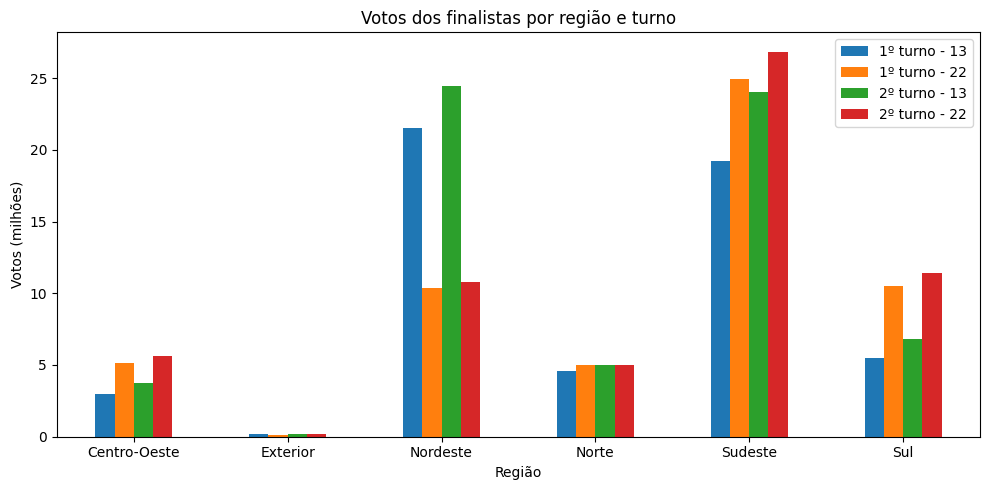

In [196]:
# Garante que as variáveis necessárias estejam definidas se a célula anterior não tiver sido executada
if "votos_regiao" not in globals() or "colunas_votos" not in globals():
    colunas_votos = ["T1_13", "T1_22", "T2_13", "T2_22"]
    regioes = {"AC": "Norte", "AP": "Norte", "AM": "Norte", "PA": "Norte", "RO": "Norte", "RR": "Norte", "TO": "Norte",
               "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste", "PB": "Nordeste",
               "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste", "SE": "Nordeste",
               "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
               "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
               "PR": "Sul", "RS": "Sul", "SC": "Sul", "ZZ": "Exterior"}


# Gráfico 1: votos dos 2 candidatos por região e turno
votos_regiao_mi = votos_regiao[colunas_votos] / 1_000_000
votos_regiao_mi.columns = ["1º turno - 13", "1º turno - 22", "2º turno - 13", "2º turno - 22"]
votos_regiao_mi.plot(kind="bar", figsize=(10, 5))
plt.title("Votos dos finalistas por região e turno")
plt.ylabel("Votos (milhões)")
plt.xlabel("Região")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

* Gráfico 2 — percentual de municípios vencidos pelo candidato 22 por estado

  O candidato 22 venceu em todos os municípios do Distrito Federal e de Rondônia nos dois turnos. Também teve percentuais elevados em vários estados do Sul, Sudeste e Centro-Oeste. Em Minas Gerais, o percentual de municípios vencidos pelo candidato 22 caiu de 47,01% no primeiro turno para 38,10% no segundo. No conjunto, o gráfico mostra que o resultado municipal varia bastante entre os estados e que, em muitos deles, a proporção de municípios vencidos pelo candidato 22 diminuiu no segundo turno. Esse indicador conta municípios, sem considerar o tamanho do eleitorado de cada um.

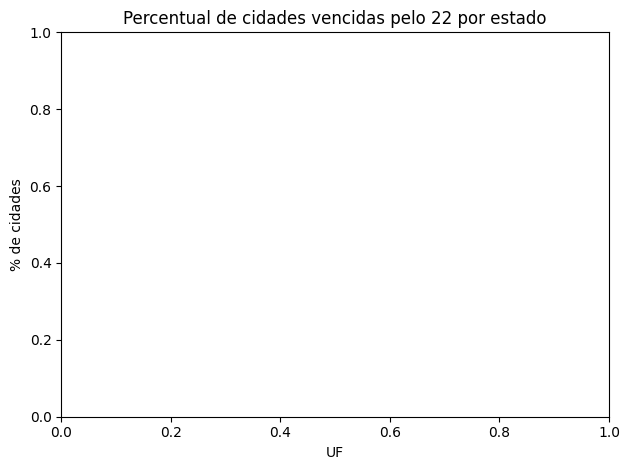

In [197]:
# Gráfico 2: percentual de cidades vencidas pelo 22, por estado, em cada turno
plt.title("Percentual de cidades vencidas pelo 22 por estado")
plt.ylabel("% de cidades")
plt.xlabel("UF")
plt.tight_layout()
plt.show()

* Gráfico 3 — composição do aumento de votos dos finalistas
  
   Somados, os dois finalistas receberam 14.098.232 votos a mais no segundo turno. A maior parcela dessa diferença corresponde aos votos que, no primeiro turno, foram para candidatos que não avançaram: 9.316.747. Também houve redução de 2.960.239 abstenções, 950.944 votos nulos e 870.302 votos brancos entre os turnos. Essa é uma decomposição dos totais agregados: ela não mostra como cada eleitor mudou seu comportamento nem permite afirmar que votos de um grupo específico foram transferidos para um candidato.

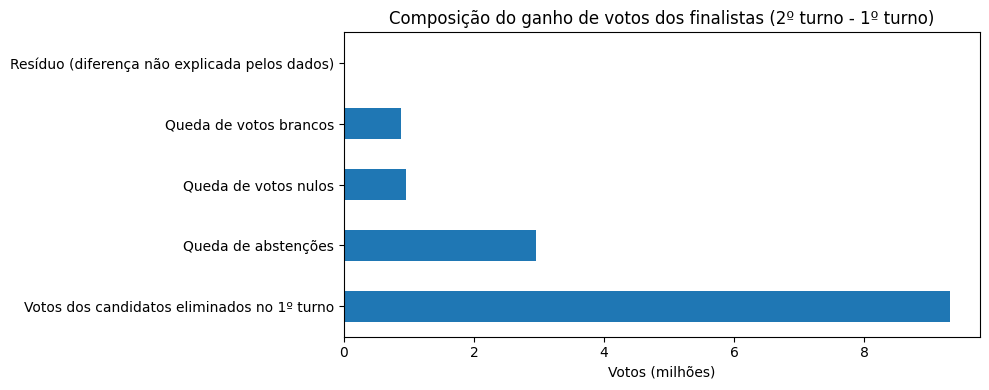

In [198]:
# Gráfico 3: de onde veio o ganho de votos dos finalistas entre os turnos
(composicao_ganho.drop("Ganho total dos finalistas")["Votos"] / 1_000_000).plot(kind="barh", figsize=(10, 4))
plt.title("Composição do ganho de votos dos finalistas (2º turno - 1º turno)")
plt.xlabel("Votos (milhões)")
plt.tight_layout()
plt.show()